# 02 - Train the same model on the naive split and the fair split

**Goal:** train one model twice, with exactly the same settings. The only difference is how the
photos were split. Then compare the scores. The gap between them is how much the naive split flatters the model.

**Not a medical tool.** Research audit of how models get fooled.

In [1]:
import sys; print(sys.executable)

/opt/anaconda3/bin/python


In [2]:
%pip install torch torchvision scikit-learn matplotlib pillow


Note: you may need to restart the kernel to use updated packages.


## Step 0 - Settings
Change these at the top, nowhere else.
- `SMOKE_TEST = True` trains on a tiny slice for 1 round, just to check the code runs (about a minute). Set it to `False` for the real run.
- `SEEDS`: each seed is one full training run. Start with one. Once it works, use `[0, 1, 2]` so you can report an average and see how much results wobble by chance.

In [11]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn
from torchvision import models
from sklearn.metrics import balanced_accuracy_score, f1_score, accuracy_score, recall_score

DATA = Path("data/archive-5")
SMOKE_TEST = False
SEEDS = [0, 1, 2]
EPOCHS = 5
BATCH = 64
LR = 3e-4

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("training on:", device)

training on: mps


## Step 1 - Shrink every photo once and keep them in memory
Reading 10,000 big JPEGs every round would be slow. So we shrink each to 224x224 pixels one time
and save them in one file. This takes a few minutes the first time, then it is instant.
(Squashing to a square changes the shape a little. That is fine, it is the same for both splits.)

In [4]:
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)
ARR, IDS = CACHE / "images224.npy", CACHE / "ids.json"

def find_image(image_id):
    for part in ("HAM10000_images_part_1", "HAM10000_images_part_2"):
        p = DATA / part / f"{image_id}.jpg"
        if p.exists():
            return p
    raise FileNotFoundError(image_id)

if not ARR.exists():
    ids = pd.read_csv(DATA / "HAM10000_metadata.csv").image_id.tolist()
    arr = np.zeros((len(ids), 224, 224, 3), dtype=np.uint8)
    for i, iid in enumerate(ids):
        arr[i] = np.asarray(Image.open(find_image(iid)).convert("RGB").resize((224, 224)))
        if i % 2000 == 0:
            print(f"{i}/{len(ids)}")
    np.save(ARR, arr); json.dump(ids, open(IDS, "w"))

images = np.load(ARR, mmap_mode="r")
row_of = {iid: i for i, iid in enumerate(json.load(open(IDS)))}
print("cached:", images.shape)

cached: (10015, 224, 224, 3)


## Step 2 - Load the splits from notebook 01
The labels (`dx`) become numbers 0-6 because the model works with numbers.

In [5]:
CLASSES = sorted(pd.read_csv(DATA / "HAM10000_metadata.csv").dx.unique())
label_of = {c: i for i, c in enumerate(CLASSES)}
print(CLASSES)

def load_split(name):
    tr = pd.read_csv(f"splits/{name}_train.csv"); te = pd.read_csv(f"splits/{name}_test.csv")
    if SMOKE_TEST:
        tr, te = tr.sample(400, random_state=0), te.sample(200, random_state=0)
    return tr, te

['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


## Step 3 - The model
We do not train from zero. **ResNet-18** has already learned to see edges, textures and shapes from
millions of everyday photos. We swap its last layer for one that outputs our 7 skin classes and
teach the whole thing on our photos (this is called *fine-tuning*).

Two choices to understand:
- **Class weights.** Most photos are harmless moles. Without help the model would just say "mole"
  and still look good. Weights make mistakes on rare classes (like melanoma) cost more.
- **We only look at the test set once, at the very end.** No picking the "best round" by peeking at
  the test score. That would be cheating in a small way and would defeat the point of this project.

In [6]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def batch_tensor(rows, augment):
    x = torch.from_numpy(np.stack([images[row_of[i]] for i in rows])).to(device)
    x = x.permute(0, 3, 1, 2).float() / 255
    if augment:  # random flips so the model does not memorise exact pixels
        h = torch.rand(len(x), device=device) < 0.5
        v = torch.rand(len(x), device=device) < 0.5
        x = torch.where(h.view(-1, 1, 1, 1), x.flip(3), x)
        x = torch.where(v.view(-1, 1, 1, 1), x.flip(2), x)
    return (x - MEAN) / STD

def make_model():
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    return m.to(device)

def predict(model, df):
    model.eval(); out = []
    with torch.no_grad():
        for s in range(0, len(df), 128):
            out.append(model(batch_tensor(df.image_id.iloc[s:s+128], False)).argmax(1).cpu())
    return torch.cat(out).numpy()

## Step 4 - Train one run and score it

In [7]:
def run(split, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    tr, te = load_split(split)
    y_tr = tr.dx.map(label_of).values; y_te = te.dx.map(label_of).values

    counts = np.bincount(y_tr, minlength=len(CLASSES)).clip(min=1)
    weights = torch.tensor(len(y_tr) / (len(CLASSES) * counts), dtype=torch.float, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=weights)

    model = make_model()
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    epochs = 1 if SMOKE_TEST else EPOCHS

    for ep in range(epochs):
        model.train(); order = np.random.permutation(len(tr)); total = 0; t0 = time.time()
        for s in range(0, len(order), BATCH):
            idx = order[s:s+BATCH]
            x = batch_tensor(tr.image_id.iloc[idx], True)
            y = torch.tensor(y_tr[idx], device=device)
            opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        print(f"  [{split} seed {seed}] epoch {ep+1}/{epochs}  loss {total/len(tr):.3f}  ({time.time()-t0:.0f}s)")

    pred = predict(model, te)          # test set used once, at the end
    res = {
        "split": split, "seed": seed,
        "accuracy": accuracy_score(y_te, pred),
        "balanced_accuracy": balanced_accuracy_score(y_te, pred),
        "macro_f1": f1_score(y_te, pred, average="macro"),
        "melanoma_recall": recall_score(y_te, pred, labels=[label_of["mel"]], average=None, zero_division=0)[0],
    }
    return res

## Step 5 - Run both splits
The only thing that changes between the two is the split name.

In [8]:
Path("results").mkdir(exist_ok=True)
results = []
for seed in SEEDS:
    for split in ("naive", "fair"):
        results.append(run(split, seed))
res = pd.DataFrame(results)
res.to_csv("results/smoke_test.csv" if SMOKE_TEST else "results/02_scores.csv", index=False)
res.round(3)

  [naive seed 0] epoch 1/5  loss 1.090  (148s)
  [naive seed 0] epoch 2/5  loss 0.806  (129s)
  [naive seed 0] epoch 3/5  loss 0.641  (129s)
  [naive seed 0] epoch 4/5  loss 0.554  (128s)
  [naive seed 0] epoch 5/5  loss 0.480  (126s)
  [fair seed 0] epoch 1/5  loss 1.081  (126s)
  [fair seed 0] epoch 2/5  loss 0.772  (126s)
  [fair seed 0] epoch 3/5  loss 0.652  (126s)
  [fair seed 0] epoch 4/5  loss 0.575  (126s)
  [fair seed 0] epoch 5/5  loss 0.445  (163s)
  [naive seed 1] epoch 1/5  loss 1.052  (166s)
  [naive seed 1] epoch 2/5  loss 0.776  (164s)
  [naive seed 1] epoch 3/5  loss 0.661  (159s)
  [naive seed 1] epoch 4/5  loss 0.601  (161s)
  [naive seed 1] epoch 5/5  loss 0.496  (167s)
  [fair seed 1] epoch 1/5  loss 1.120  (171s)
  [fair seed 1] epoch 2/5  loss 0.763  (163s)
  [fair seed 1] epoch 3/5  loss 0.681  (164s)
  [fair seed 1] epoch 4/5  loss 0.574  (164s)
  [fair seed 1] epoch 5/5  loss 0.493  (156s)
  [naive seed 2] epoch 1/5  loss 1.091  (157s)
  [naive seed 2] epoch 

,split,seed,accuracy,balanced_accuracy,macro_f1,melanoma_recall
0,naive,0,0.761,0.790,0.669,0.717
1,fair,0,0.683,0.657,0.577,0.814
2,naive,1,0.675,0.727,0.631,0.861
3,fair,1,0.754,0.674,0.594,0.487
4,naive,2,0.801,0.731,0.696,0.717
5,fair,2,0.669,0.640,0.518,0.640


## Step 6 - Compare
Read the table like this:
- **accuracy** is the number people usually quote. Remember the do-nothing baseline is about 67%.
- **balanced_accuracy** and **macro_f1** treat every class equally, so rare cancers count as much as common moles. These are the honest ones.
- **melanoma_recall**: of all real melanomas in the test set, how many did the model catch. This is the one that matters most medically.

accuracy        balanced_accuracy        macro_f1         \
          mean    std              mean    std     mean    std   
split                                                            
fair     0.702  0.046             0.657  0.017    0.563  0.040   
naive    0.746  0.064             0.749  0.036    0.666  0.033   

      melanoma_recall         
                 mean    std  
split                         
fair            0.647  0.163  
naive           0.765  0.083

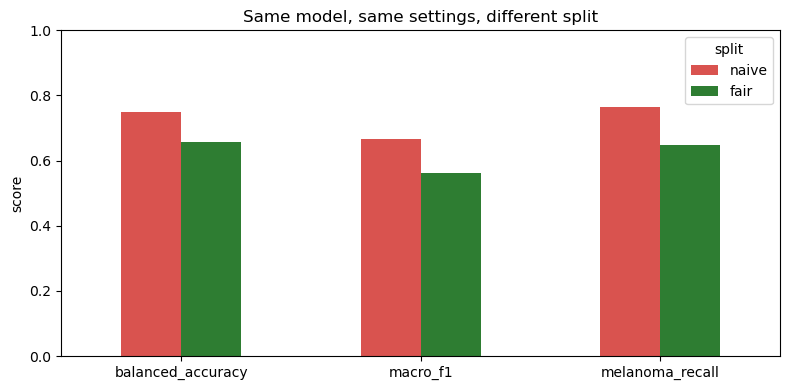

In [9]:
summary = res.groupby("split")[["accuracy", "balanced_accuracy", "macro_f1", "melanoma_recall"]].agg(["mean", "std"]).round(3)
display(summary)

metrics = ["balanced_accuracy", "macro_f1", "melanoma_recall"]
means = res.groupby("split")[metrics].mean().loc[["naive", "fair"]]
means.T.plot.bar(figsize=(8, 4), rot=0, color=["#d9534f", "#2e7d32"])
plt.ylabel("score"); plt.title("Same model, same settings, different split"); plt.ylim(0, 1); plt.tight_layout()
if not SMOKE_TEST:
    plt.savefig("results/02_naive_vs_fair.png", dpi=150)
plt.show()

### Write down for your README
- naive balanced accuracy: ____  /  fair: ____
- naive melanoma recall: ____  /  fair: ____
- gap (naive minus fair): ____

**If the gap is small:** that is a real result. It would mean this dataset leaks less than people fear, or that 5 training rounds is too short to memorise much. Report it honestly and run more seeds.

**Next (notebook 03):** hide the lesion and see whether the model still scores, and draw heatmaps of where it looks.